# Chapter 4 — Animal image classification

Give the model a photo and predict **cat** or **dog**. We will view images, prepare training data, train a small convolutional neural network (CNN), evaluate unseen photos, and try a photo of your own.

The dataset is the 3,000-photo cats-and-dogs subset used in [Google's image classification tutorial](https://www.tensorflow.org/tutorials/images/transfer_learning). Images come from the Microsoft/Kaggle Cats vs Dogs collection.

Use the `.venv315` notebook kernel. Required packages are `torch`, `Pillow`, `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. If a package is missing, install it in a separate cell with `%pip install torch Pillow numpy pandas matplotlib scikit-learn`, then restart the kernel and run from the top.

In [8]:
from pathlib import Path
import copy
import random
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)

CLASS_NAMES = ['Cat', 'Dog']
IMAGE_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 8
print('PyTorch:', torch.__version__)


PyTorch: 2.15.0


## Load the photographs

The first run downloads about 65 MB if the image folders are missing. Subsequent runs reuse the local images.

The archive has 2,000 training photos and 1,000 photos in a folder named `validation`. We reserve that entire folder as our final test set, and split the original training photos into 1,600 training and 400 validation examples. Validation selects the best training epoch. Test images are evaluated after training.

In [9]:
DATA_ROOT = Path('data')
DATA_DIR = DATA_ROOT / 'cats_and_dogs_filtered'
DATA_URL = 'https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip'

if not DATA_DIR.is_dir():
    DATA_ROOT.mkdir(exist_ok=True)
    archive_path = DATA_ROOT / 'cats_and_dogs_filtered.zip'
    partial_path = archive_path.with_suffix('.zip.part')
    if not archive_path.exists():
        print('Downloading cat and dog photographs...')
        urllib.request.urlretrieve(DATA_URL, partial_path)
        partial_path.replace(archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            destination = (DATA_ROOT / member.filename).resolve()
            destination.relative_to(DATA_ROOT.resolve())
        archive.extractall(DATA_ROOT)

records = []
for split in ['train', 'validation']:
    for label, folder in enumerate(['cats', 'dogs']):
        for path in sorted((DATA_DIR / split / folder).glob('*.jpg')):
            records.append({'path': path, 'label': label, 'source_split': split})
photos = pd.DataFrame(records)
assert len(photos) == 3000, 'Expected all 3,000 photos. Check the extracted dataset.'
display(pd.crosstab(photos['source_split'], photos['label']).rename(columns=dict(enumerate(CLASS_NAMES))))


label,Cat,Dog
source_split,,
train,1000,1000
validation,500,500


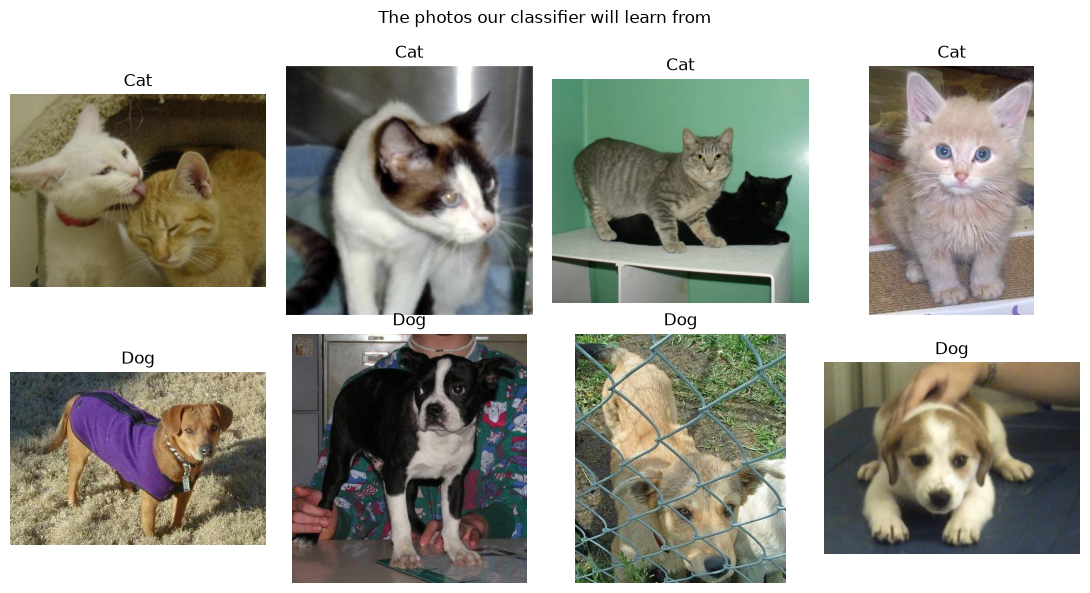

In [10]:
preview = photos.groupby('label', group_keys=False).sample(n=4, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, row in zip(axes.flat, preview.itertuples()):
    with Image.open(row.path) as image:
        ax.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    ax.set_title(CLASS_NAMES[row.label])
    ax.axis('off')
fig.suptitle('The photos our classifier will learn from')
plt.tight_layout()
plt.show()


## Turn images into model inputs

Resize every photo to 64 × 64 pixels, convert to RGB, and scale pixel values into [−1, 1]. PyTorch expects the color-channel dimension first, giving each image a shape of `(3, 64, 64)`.

The labels are `0 = Cat` and `1 = Dog`. Filenames identify images and are excluded from the model inputs.

In [11]:
train_pool = photos.loc[photos['source_split'] == 'train'].reset_index(drop=True)
test_rows = photos.loc[photos['source_split'] == 'validation'].reset_index(drop=True)
train_rows, val_rows = train_test_split(
    train_pool, test_size=0.20, random_state=SEED, stratify=train_pool['label']
)
train_rows = train_rows.reset_index(drop=True)
val_rows = val_rows.reset_index(drop=True)

def image_tensor(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image = ImageOps.fit(image, IMAGE_SIZE, method=Image.Resampling.BILINEAR)
        pixels = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(pixels.transpose(2, 0, 1).copy())

def load_photos(rows):
    images = torch.stack([image_tensor(path) for path in rows['path']])
    labels = torch.tensor(rows['label'].to_numpy(), dtype=torch.long)
    return TensorDataset(images, labels)

train_data = load_photos(train_rows)
val_data = load_photos(val_rows)
test_data = load_photos(test_rows)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE)
print(f'Train: {len(train_data)}, validation: {len(val_data)}, test: {len(test_data)}')
print('One image shape:', tuple(train_data[0][0].shape))


Train: 1600, validation: 400, test: 1000
One image shape: (3, 64, 64)


## Build a convolutional neural network

Convolution layers learn visual patterns from the training images. Pooling reduces spatial size, and the final layers produce two scores, one for each animal class. Cross-entropy loss trains these scores against the correct labels.

This small network trains from scratch on the CPU. The goal is an understandable first image project. Training can take a few minutes.

In [12]:
model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(64 * 8 * 8, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 2)
)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')


Trainable parameters: 285,922


In [13]:
def evaluate(loader):
    model.eval()
    total_loss = 0.0
    predicted_labels = []
    actual_labels = []
    with torch.inference_mode():
        for images, labels in loader:
            scores = model(images)
            total_loss += loss_function(scores, labels).item() * len(labels)
            predicted_labels.extend(scores.argmax(dim=1).tolist())
            actual_labels.extend(labels.tolist())
    return (
        total_loss / len(loader.dataset),
        accuracy_score(actual_labels, predicted_labels),
        np.array(actual_labels),
        np.array(predicted_labels)
    )

history = []
best_val_loss = float('inf')
best_weights = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    correct = 0
    for images, labels in train_loader:
        flip_mask = torch.rand(len(images)) < 0.5
        images[flip_mask] = images[flip_mask].flip(dims=[3])
        optimizer.zero_grad()
        scores = model(images)
        loss = loss_function(scores, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (scores.argmax(dim=1) == labels).sum().item()
    val_loss, val_accuracy, _, _ = evaluate(val_loader)
    history.append({
        'epoch': epoch + 1,
        'train_loss': total_loss / len(train_data),
        'train_accuracy': correct / len(train_data),
        'val_loss': val_loss,
        'val_accuracy': val_accuracy
    })
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch + 1}/{EPOCHS} | train accuracy {correct / len(train_data):.1%} | validation accuracy {val_accuracy:.1%}', flush=True)

model.load_state_dict(best_weights)
model.eval()
print('Restored the epoch with the lowest validation loss.')


Epoch 1/8 | train accuracy 49.1% | validation accuracy 53.8%
Epoch 2/8 | train accuracy 55.2% | validation accuracy 56.5%
Epoch 3/8 | train accuracy 60.8% | validation accuracy 59.5%
Epoch 4/8 | train accuracy 63.8% | validation accuracy 67.8%
Epoch 5/8 | train accuracy 68.8% | validation accuracy 69.5%
Epoch 6/8 | train accuracy 71.3% | validation accuracy 69.2%
Epoch 7/8 | train accuracy 73.6% | validation accuracy 67.8%
Epoch 8/8 | train accuracy 75.6% | validation accuracy 71.0%
Restored the epoch with the lowest validation loss.


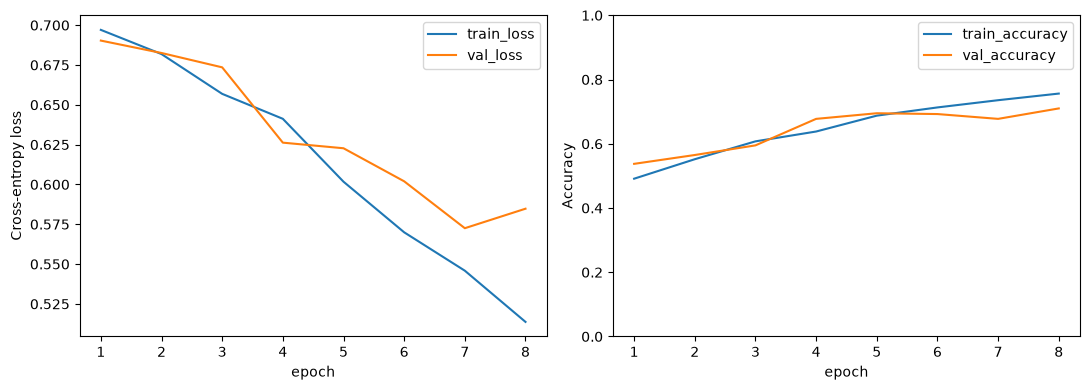

In [14]:
learning = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
learning.plot(x='epoch', y=['train_loss', 'val_loss'], ax=axes[0])
axes[0].set_ylabel('Cross-entropy loss')
learning.plot(x='epoch', y=['train_accuracy', 'val_accuracy'], ax=axes[1])
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()


## Evaluate unseen photos

The majority-class baseline is 50% on this balanced test set. Accuracy measures the fraction of correct predictions. The confusion matrix shows which animals were confused.

These scores measure this dataset and split. New photos with different backgrounds, lighting, or framing may perform differently.

Majority-class baseline: 50.0%
Test accuracy: 70.5% (705/1000 correct)
              precision    recall  f1-score   support

         Cat       0.66      0.85      0.74       500
         Dog       0.79      0.56      0.65       500

    accuracy                           0.70      1000
   macro avg       0.72      0.71      0.70      1000
weighted avg       0.72      0.70      0.70      1000



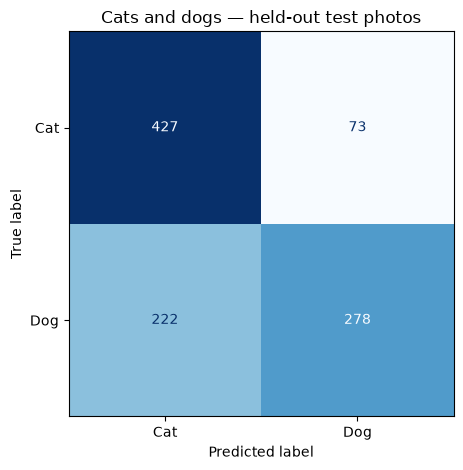

In [15]:
test_loss, test_accuracy, actual, predicted = evaluate(test_loader)
print('Majority-class baseline: 50.0%')
print(f'Test accuracy: {test_accuracy:.1%} ({(actual == predicted).sum()}/{len(actual)} correct)')
print(classification_report(actual, predicted, labels=[0, 1], target_names=CLASS_NAMES, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    actual, predicted, labels=[0, 1], display_labels=CLASS_NAMES,
    cmap='Blues', colorbar=False
)
plt.title('Cats and dogs — held-out test photos')
plt.tight_layout()
plt.show()


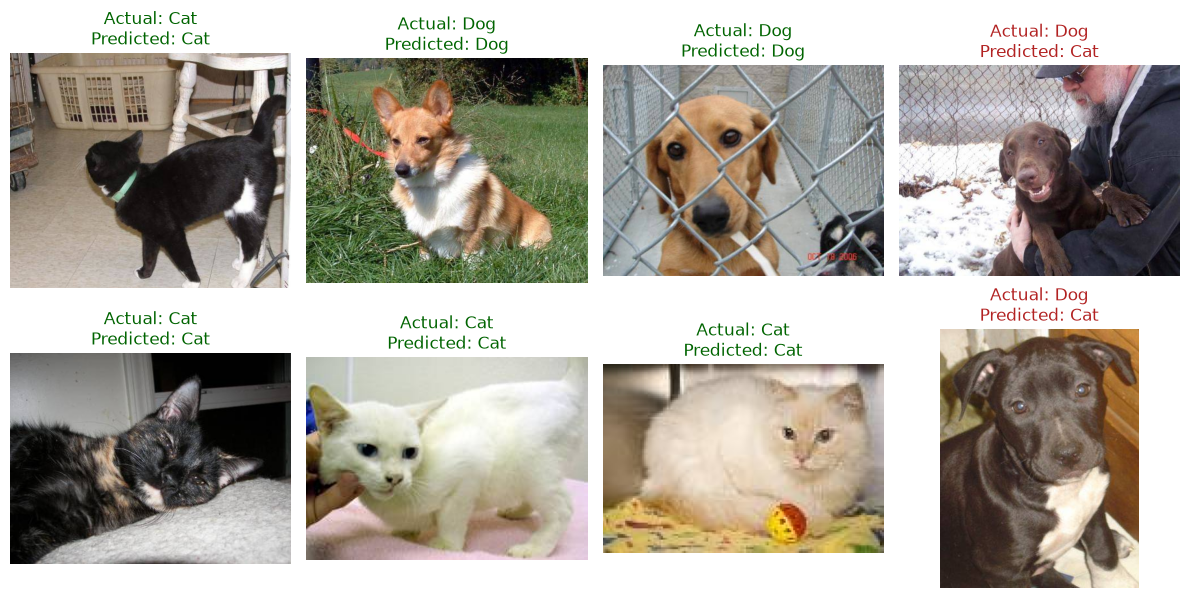

In [16]:
sample_indices = np.random.default_rng(SEED).choice(len(test_rows), size=8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, index in zip(axes.flat, sample_indices):
    with Image.open(test_rows.iloc[index]['path']) as image:
        ax.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    correct = actual[index] == predicted[index]
    ax.set_title(
        f'Actual: {CLASS_NAMES[actual[index]]}\nPredicted: {CLASS_NAMES[predicted[index]]}',
        color='darkgreen' if correct else 'firebrick'
    )
    ax.axis('off')
plt.tight_layout()
plt.show()


## Try your own animal photo

Set `PHOTO_PATH` to a local `.jpg` or `.png` file, then rerun the next cell. The default uses a held-out test photo so the cell works immediately.

The model chooses between cat and dog for every input. Its softmax score is an uncalibrated model score, including when the photo contains another animal or no animal.

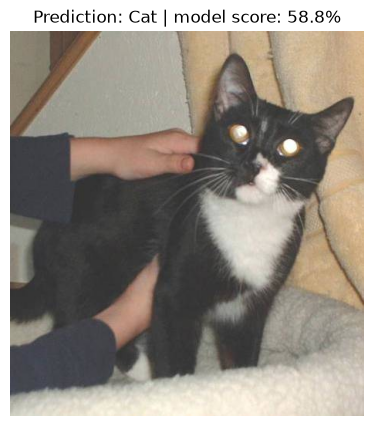

Cat    0.587514
Dog    0.412486
Name: Model score, dtype: float32

In [17]:
PHOTO_PATH = test_rows.iloc[0]['path']
# Example: PHOTO_PATH = Path('/absolute/path/to/my_cat.jpg')

def predict_photo(path):
    model.eval()
    with torch.inference_mode():
        probabilities = torch.softmax(model(image_tensor(path).unsqueeze(0)), dim=1)[0]
    label = int(probabilities.argmax())
    with Image.open(path) as image:
        plt.figure(figsize=(5, 5))
        plt.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    plt.title(f'Prediction: {CLASS_NAMES[label]} | model score: {float(probabilities[label]):.1%}')
    plt.axis('off')
    plt.show()
    return pd.Series(probabilities.numpy(), index=CLASS_NAMES, name='Model score')

display(predict_photo(PHOTO_PATH))


## What to inspect

Look at the photo previews and the red prediction labels to identify errors. Compare the training and validation curves to see whether the model begins to memorize its training photos. As a later extension, use a pretrained image model and compare it on the same held-out test set.

Rerunning the build-model and training cells resets and retrains the network. Run the notebook from the top for a fresh reproducible experiment.